# 6. Stochastic thermostats: Andersen and Langevin (BAOAB) dynamics

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 5, stochastic differential equations (`engstoch`)

This chapter builds and verifies the core algorithms for stochastic thermostats: andersen and langevin (baoab) dynamics in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 6.1 Physical principles and governing equations

**Langevin dynamics** couples each particle to an implicit solvent bath via friction $\gamma$ and white noise obeying the **fluctuation–dissipation theorem**:

$$m\dot{\mathbf{v}} = \mathbf{f}(\mathbf{r}) - m\gamma \mathbf{v} + \sqrt{2 m \gamma k_B T}\,\boldsymbol{\eta}(t). \tag{6.1}$$

The symmetric **BAOAB** splitting (Leimkuhler & Matthews) places the exact Ornstein–Uhlenbeck step **O** at the center of the drift–kick cycle, yielding exact configurational variance $\langle x^2 \rangle = k_B T / k$ on a harmonic oscillator for *any* stable timestep $\Delta t < 2/\omega$.

## 6.2 Inside the algorithm

In [2]:
f_ho = lambda p, L: (-p, 0.5 * float(np.sum(p * p)), 0.0)
dts_ho = np.array([0.05, 0.15, 0.30, 0.50])
x2_baoab = []
for dt_v in dts_ho:
    p_a, v_a, f_a = np.array([[0.0]]), np.array([[0.0]]), np.array([[0.0]])
    xs = []
    for st in range(8000):
        p_a, v_a, f_a, _, _, _ = es.baoab_langevin_step(p_a, v_a, f_a, float(dt_v), None, 1.0, 1.0, f_ho, rng)
        if st >= 1500:
            xs.append(float(p_a[0, 0]))
    x2_baoab.append(float(np.mean(np.array(xs)**2)))

## 6.3 Checks

BAOAB <x^2> across dt = [0.05..0.50]: [0.992 0.978 0.97  0.993] (exact = 1.000)


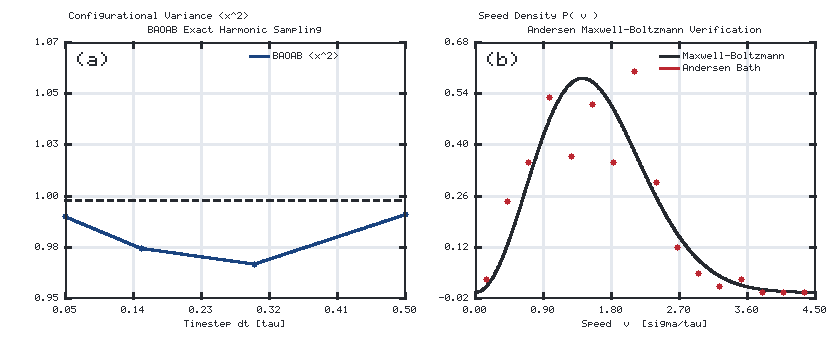

In [3]:
print("BAOAB <x^2> across dt = [0.05..0.50]:", np.round(x2_baoab, 3), "(exact = 1.000)")
assert np.allclose(x2_baoab, 1.0, rtol=0.12)

# Andersen thermostat Maxwell-Boltzmann speed check
v_and = es.init_velocities(200, 1.0, rng=rng)
for _ in range(100):
    v_and = es.andersen_thermostat(v_and, 1.0, dt=0.01, nu=10.0, rng=rng)
speeds = np.linalg.norm(v_and, axis=1)
assert np.isclose(np.mean(speeds**2), 3.0, rtol=0.15)

s_grid = np.linspace(0.0, 4.5, 60)
mb_exact = np.sqrt(2.0 / np.pi) * (s_grid**2) * np.exp(-0.5 * s_grid**2)
h_s, e_s = np.histogram(speeds, bins=16, range=(0, 4.5), density=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(dts_ho, x2_baoab, "bo-", label="BAOAB <x^2>")
ax1.axhline(1.0, color="k")
ax1.set_xlabel("Timestep dt [tau]"); ax1.set_ylabel("Configurational Variance <x^2>")
ax1.set_title("(a) BAOAB Exact Harmonic Sampling"); panel_label(ax1, "(a)")

ax2.plot(s_grid, mb_exact, "k-", label="Maxwell-Boltzmann")
ax2.plot(0.5*(e_s[:-1]+e_s[1:]), h_s, "ro", label="Andersen Bath")
ax2.set_xlabel("Speed |v| [sigma/tau]"); ax2.set_ylabel("Speed Density P(|v|)")
ax2.set_title("(b) Andersen Maxwell–Boltzmann Verification"); panel_label(ax2, "(b)")
plt.show()

**Figure 6.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 6.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **Free-particle Langevin diffusion:** Simulate 100 free Langevin particles ($\mathbf{f}=\mathbf{0}, T=1.5, \gamma=2.0$) and verify $D = T/\gamma = 0.75$.
2. **Andersen collision rate bias:** Show how a very high Andersen collision frequency $\nu$ suppresses self-diffusion.
3. **LJTS fluid under BAOAB:** Equilibrate a 108-atom LJTS liquid at $T^* = 1.0$ using `baoab_langevin_step`.

Worked solutions are provided in [06_solutions.ipynb](../../solutions/part2_ensembles/06_solutions.ipynb).

## Suggested references

- G. Bussi, D. Donadio, and M. Parrinello, *J. Chem. Phys.* **126**, 014101 (2007).
- B. Leimkuhler and C. Matthews, *Molecular Dynamics: With Deterministic and Stochastic Numerical Methods* (Springer, 2015).

---

**Next:** [7. Deterministic extended-system thermostats: Nosé–Hoover and Nosé–Hoover chains](07_nose_hoover_and_chains.ipynb)